# Preprocessing A - Magnitude Representation and Window-Level Split

This notebook defines the magnitude-based preprocessing contract used by model versions V1-V4. Every decision follows from the EDA: acquisition windows are kept separate to prevent leakage, out-of-bounds labels are clipped without changing presence masks, and sensor-specific signal shifts are handled using statistics estimated exclusively from training windows. V5 uses the alternative signed I/Q contract documented in `03b_preprocessing_signed_iq.ipynb`.

## 1. Setup and authentication

The dataset is read from the Hugging Face cache. The token is requested through a hidden field if it is not available as `HF_TOKEN`.

In [1]:
%matplotlib inline

import getpass
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from preprocessing import (
    MAX_PEOPLE, ROOM_X_METERS, ROOM_Y_METERS, PreprocessingConfig,
    build_sorted_targets, clip_valid_coordinates, iq_to_amplitude,
    normalize_per_radar, per_radar_moments, transform_signal,
)

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
if not HF_TOKEN:
    raise RuntimeError('A Hugging Face token is required.')

api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])

REPO_ID = 'HAEEAI/multi-person-localization'
TOTAL_WINDOWS = 24
ARTIFACT_DIR = Path('src/artifacts') if (Path.cwd() / 'src').exists() else Path('artifacts')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti


## 2. Resolve dataset files

Hugging Face reuses the files downloaded during the EDA, so this step should normally complete without transferring the dataset again.

In [2]:
window_paths = {}
for window_index in range(TOTAL_WINDOWS):
    filename = f'data/window_{window_index:06d}.npz'
    path = hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    )
    window_paths[window_index] = Path(path)
print(f'{len(window_paths)} acquisition windows are ready.')

24 acquisition windows are ready.


## 3. Define a leakage-free split

Each acquisition window contains a single occupancy level. The validation set therefore contains one complete window for each class from zero to four people. The selected windows also span different acquisition-level amplitude regimes. All remaining windows are used for training.

This validation distribution is deliberately balanced rather than identical to the global distribution. We will report both global metrics and metrics by occupancy level.

In [3]:
VALIDATION_WINDOWS = [3, 9, 14, 18, 23]  # occupancy 2, 4, 3, 1, 0
TRAIN_WINDOWS = [index for index in range(TOTAL_WINDOWS) if index not in VALIDATION_WINDOWS]

assert set(TRAIN_WINDOWS).isdisjoint(VALIDATION_WINDOWS)
assert sorted(TRAIN_WINDOWS + VALIDATION_WINDOWS) == list(range(TOTAL_WINDOWS))

split = {
    'seed': SEED,
    'train_windows': TRAIN_WINDOWS,
    'validation_windows': VALIDATION_WINDOWS,
    'rationale': 'One complete validation window for each occupancy level; no frame-level leakage.',
}
with (ARTIFACT_DIR / 'data_split.json').open('w', encoding='utf-8') as handle:
    json.dump(split, handle, indent=2)

print(f'Training windows:   {TRAIN_WINDOWS}')
print(f'Validation windows: {VALIDATION_WINDOWS}')
print(f'Training frames:    {len(TRAIN_WINDOWS) * 7500:,}')
print(f'Validation frames:  {len(VALIDATION_WINDOWS) * 7500:,}')

Training windows:   [0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 19, 20, 21, 22]
Validation windows: [3, 9, 14, 18, 23]
Training frames:    142,500
Validation frames:  37,500


## 4. Verify occupancy composition

The split is checked directly from the masks rather than relying on manually assigned scenario labels.

People | Training frames | Validation frames
--------------------------------------------
     0 |           7,500 |             7,500
     1 |          37,500 |             7,500
     2 |          30,000 |             7,500
     3 |          22,500 |             7,500
     4 |          45,000 |             7,500


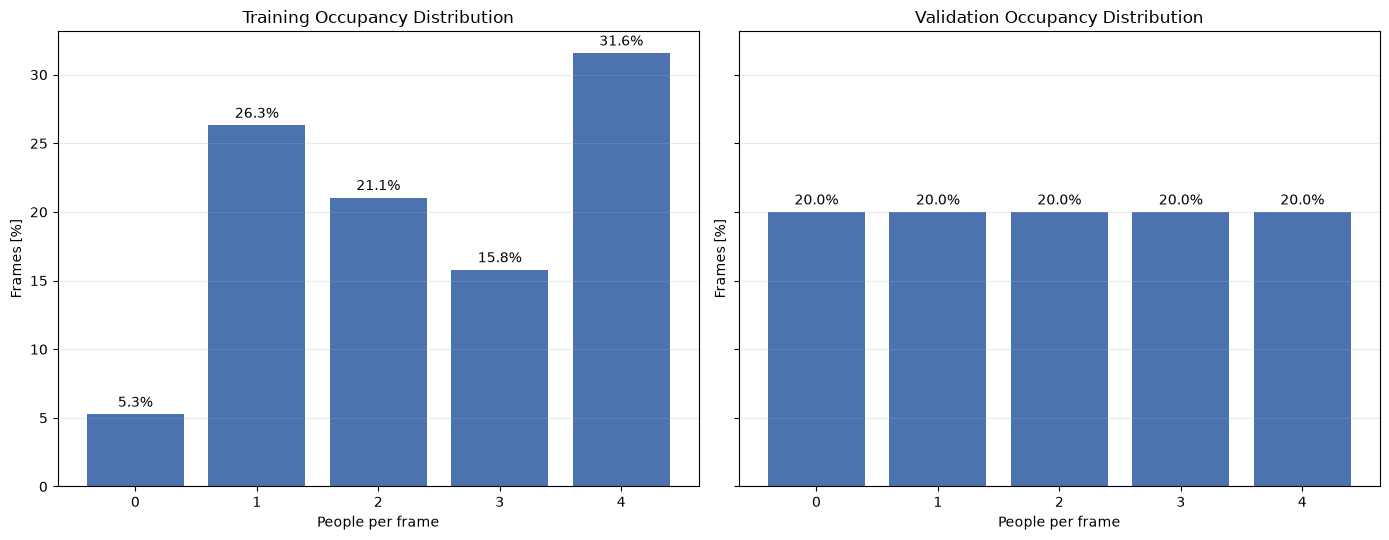

In [4]:
def occupancy_for_windows(indices):
    counts = np.zeros(MAX_PEOPLE + 1, dtype=np.int64)
    for index in indices:
        with np.load(window_paths[index], allow_pickle=False) as data:
            occupancy = np.asarray(data['people_mask']).astype(bool).sum(axis=1)
        counts += np.bincount(occupancy, minlength=MAX_PEOPLE + 1)
    return counts

train_occupancy = occupancy_for_windows(TRAIN_WINDOWS)
validation_occupancy = occupancy_for_windows(VALIDATION_WINDOWS)

print('People | Training frames | Validation frames')
print('-' * 44)
for people in range(MAX_PEOPLE + 1):
    print(f'{people:>6} | {train_occupancy[people]:>15,} | {validation_occupancy[people]:>17,}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for axis, counts, title in zip(
    axes, [train_occupancy, validation_occupancy], ['Training', 'Validation']
):
    percentages = counts / counts.sum() * 100
    bars = axis.bar(np.arange(5), percentages, color='#4c72b0')
    axis.bar_label(bars, fmt='%.1f%%', padding=3)
    axis.set(title=f'{title} Occupancy Distribution', xlabel='People per frame', ylabel='Frames [%]')
    axis.set_xticks(np.arange(5))
    axis.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Ground-truth preprocessing

Out-of-bounds investigation showed continuous entrance/exit trajectories rather than isolated corrupt labels. We therefore preserve every valid presence mask and clip coordinates to the official room domain before normalisation. People are assigned to four deterministic output slots by lexicographic `(x, y)` order.

In [5]:
target_examples = []
clipped_by_split = {'training': 0, 'validation': 0}
for index in range(TOTAL_WINDOWS):
    with np.load(window_paths[index], allow_pickle=False) as data:
        original_xy = np.asarray(data['people_xy'])
        mask = np.asarray(data['people_mask']).astype(bool)
    clipped_xy = clip_valid_coordinates(original_xy, mask)
    clipped_count = int(np.any(clipped_xy[mask] != original_xy[mask], axis=1).sum())
    split_name = 'validation' if index in VALIDATION_WINDOWS else 'training'
    clipped_by_split[split_name] += clipped_count
    if index in VALIDATION_WINDOWS:
        target_examples.append(build_sorted_targets(original_xy[:10], mask[:10]))

example_targets = np.concatenate(target_examples, axis=0)
total_clipped = sum(clipped_by_split.values())
assert total_clipped == 1081, f'Expected 1,081 clipped observations, found {total_clipped}'
assert np.isfinite(example_targets).all()
assert example_targets[..., 1:].min() >= 0.0
assert example_targets[..., 1:].max() <= 1.0
print(f"Clipped training observations:   {clipped_by_split['training']:,}")
print(f"Clipped validation observations: {clipped_by_split['validation']:,}")
print(f'Clipped total observations:      {total_clipped:,}')
print('Target shape:', example_targets.shape)
print('Example target [confidence, x_norm, y_norm]:')
print(example_targets[0])

Clipped training observations:   1,065
Clipped validation observations: 16
Clipped total observations:      1,081
Target shape: (50, 4, 3)
Example target [confidence, x_norm, y_norm]:
[[1.         0.14933184 0.6282016 ]
 [1.         0.72954446 0.152174  ]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]


## 6. Signal preprocessing configuration

The baseline retains all six radars, all three antennas, and all 120 range bins. I/Q samples are converted to magnitude and compressed with `log(1 + amplitude)` to reduce the large dynamic range observed in the EDA.

EMA background subtraction is not enabled in the first baseline. Although it can suppress static clutter, a causal EMA can gradually absorb stationary people and may therefore harm seated-subject scenarios. It remains an explicit experimental variant rather than an undocumented default.

In [6]:
BASELINE_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5),
    antenna_mode='none',
    range_bin_start=0,
    range_bin_stop=120,
    log_compression=True,
    background_mode='none',
    ema_alpha=0.98,
)
BASELINE_CONFIG.validate()
print(BASELINE_CONFIG)

PreprocessingConfig(radar_indices=(0, 1, 2, 3, 4, 5), antenna_mode='none', range_bin_start=0, range_bin_stop=120, log_compression=True, background_mode='none', ema_alpha=0.98, epsilon=1e-06)


## 7. Inspect raw and log-compressed signal distributions

A representative subset of the first training window is used only for visualisation. The transformation itself is deterministic and is applied identically to every window.

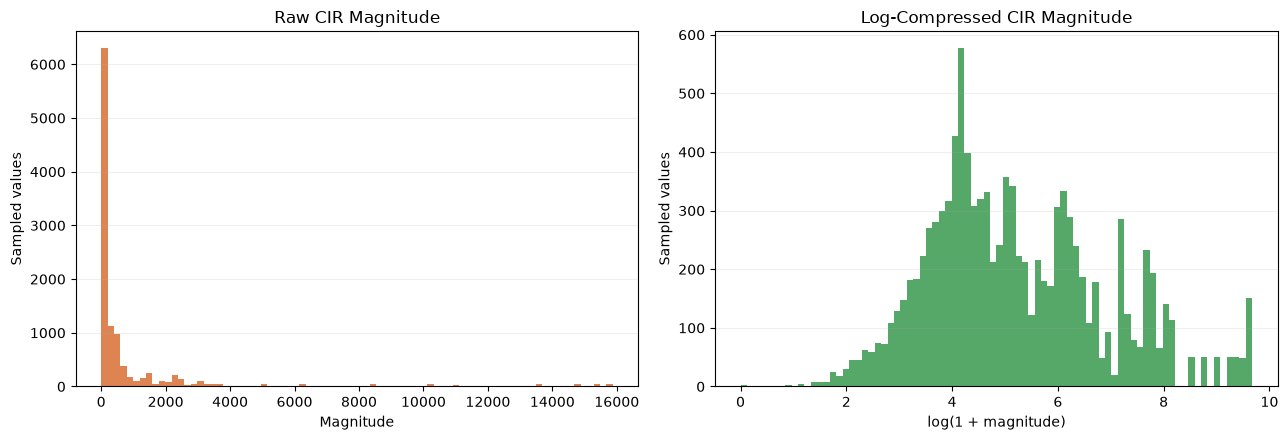

Transformed feature shape: (250, 6, 3, 120)


In [7]:
with np.load(window_paths[TRAIN_WINDOWS[0]], allow_pickle=False) as data:
    sample_iq = np.asarray(data['radar_cir_iq'][:250])

raw_amplitude = iq_to_amplitude(sample_iq)
log_features = transform_signal(sample_iq, BASELINE_CONFIG)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(raw_amplitude.ravel()[::50], bins=80, color='#dd8452')
axes[0].set(title='Raw CIR Magnitude', xlabel='Magnitude', ylabel='Sampled values')
axes[1].hist(log_features.ravel()[::50], bins=80, color='#55a868')
axes[1].set(title='Log-Compressed CIR Magnitude', xlabel='log(1 + magnitude)', ylabel='Sampled values')
for axis in axes:
    axis.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Transformed feature shape:', log_features.shape)

## 8. Estimate normalisation statistics from training windows only

The EDA found systematic amplitude differences between radars. We therefore estimate one mean and standard deviation per selected radar while preserving antenna and range-bin structure. Validation windows are never used in this calculation. Windows are processed sequentially to keep peak memory bounded.

In [8]:
STATISTICS_CHUNK_SIZE = 256
assert BASELINE_CONFIG.background_mode == 'none', (
    'Chunked statistics must not reset EMA state. Use a stateful EMA implementation '
    'before enabling background subtraction.'
)

def training_feature_blocks():
    for position, index in enumerate(TRAIN_WINDOWS, start=1):
        print(f'[{position:02d}/{len(TRAIN_WINDOWS):02d}] Statistics from window {index:06d}')
        with np.load(window_paths[index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            for start in range(0, len(radar), STATISTICS_CHUNK_SIZE):
                yield transform_signal(
                    radar[start:start + STATISTICS_CHUNK_SIZE], BASELINE_CONFIG
                )

radar_mean, radar_std, values_per_radar = per_radar_moments(training_feature_blocks())
assert np.all(radar_std > 0)
print('\nPer-radar log-amplitude mean:', radar_mean)
print('Per-radar log-amplitude std: ', radar_std)
print(f'Values used per radar: {values_per_radar:,}')

[01/19] Statistics from window 000000
[02/19] Statistics from window 000001
[03/19] Statistics from window 000002
[04/19] Statistics from window 000004
[05/19] Statistics from window 000005
[06/19] Statistics from window 000006
[07/19] Statistics from window 000007
[08/19] Statistics from window 000008
[09/19] Statistics from window 000010
[10/19] Statistics from window 000011
[11/19] Statistics from window 000012
[12/19] Statistics from window 000013
[13/19] Statistics from window 000015
[14/19] Statistics from window 000016
[15/19] Statistics from window 000017
[16/19] Statistics from window 000019
[17/19] Statistics from window 000020
[18/19] Statistics from window 000021
[19/19] Statistics from window 000022

Per-radar log-amplitude mean: [5.519326  5.4170136 5.4524097 5.4463177 5.4428096 5.3198543]
Per-radar log-amplitude std:  [1.672727  1.7270064 1.7676206 1.7149378 1.7848368 1.6998575]
Values used per radar: 51,300,000


## 9. Validate normalisation on unseen validation windows

Validation means are not expected to be exactly zero because the EDA identified acquisition-level shift. Large departures would reveal a potentially difficult domain gap.

In [9]:
validation_summary = []
for index in VALIDATION_WINDOWS:
    value_sum = 0.0
    value_square_sum = 0.0
    value_count = 0
    maximum = 0.0
    with np.load(window_paths[index], allow_pickle=False) as data:
        radar = data['radar_cir_iq']
        for start in range(0, len(radar), STATISTICS_CHUNK_SIZE):
            features = transform_signal(
                radar[start:start + STATISTICS_CHUNK_SIZE], BASELINE_CONFIG
            )
            normalized = normalize_per_radar(
                features, radar_mean, radar_std, BASELINE_CONFIG.epsilon
            )
            value_sum += float(normalized.sum(dtype=np.float64))
            value_square_sum += float(np.square(normalized, dtype=np.float64).sum())
            value_count += normalized.size
            maximum = max(maximum, float(np.max(np.abs(normalized))))
    mean_value = value_sum / value_count
    std_value = np.sqrt(max(value_square_sum / value_count - mean_value**2, 0.0))
    validation_summary.append((index, mean_value, std_value, maximum))

print('Window | Normalised mean | Normalised std | Maximum absolute value')
print('-' * 68)
for index, mean_value, std_value, maximum in validation_summary:
    print(f'{index:>6} | {mean_value:>15.4f} | {std_value:>14.4f} | {maximum:>22.4f}')

Window | Normalised mean | Normalised std | Maximum absolute value
--------------------------------------------------------------------
     3 |          0.0069 |         1.0053 |                 3.2996
     9 |         -0.0235 |         1.0080 |                 3.2996
    14 |         -0.0063 |         0.9975 |                 3.2996
    18 |          0.0165 |         0.9966 |                 3.2996
    23 |          0.0149 |         0.9972 |                 3.1758


## 10. Save the preprocessing contract

The model and `submission/code.py` must use exactly these constants. Saving them as JSON makes the training run reproducible and prevents accidental train/inference mismatch.

In [10]:
preprocessing_artifact = {
    'config': {**asdict(BASELINE_CONFIG), 'radar_indices': list(BASELINE_CONFIG.radar_indices)},
    'radar_mean': radar_mean.tolist(),
    'radar_std': radar_std.tolist(),
    'room_bounds_m': {'x': [0.0, ROOM_X_METERS], 'y': [0.0, ROOM_Y_METERS]},
    'target_format': '[confidence, x_normalized, y_normalized]',
    'target_order': 'lexicographic x then y',
    'clipped_observations': clipped_by_split,
    'clipped_observations_total': total_clipped,
    'statistics_source_windows': TRAIN_WINDOWS,
}
with (ARTIFACT_DIR / 'preprocessing_config.json').open('w', encoding='utf-8') as handle:
    json.dump(preprocessing_artifact, handle, indent=2)

print('Saved:', (ARTIFACT_DIR / 'data_split.json').resolve())
print('Saved:', (ARTIFACT_DIR / 'preprocessing_config.json').resolve())

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\data_split.json
Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\preprocessing_config.json


## 11. Conclusions for magnitude-based experiments V1-V4

### Final preprocessing contract

The baseline preprocessing pipeline is now explicit, reproducible, and leakage-free. The 24 acquisition windows are divided into 19 training windows (142,500 frames) and 5 validation windows (37,500 frames), with no window shared between the two sets. The validation set contains one complete window for each occupancy level from zero to four people. This produces a deliberately balanced validation benchmark and makes it possible to identify failures that a single aggregate score could hide, particularly false positives in the empty room and missed detections in crowded scenes.

A frame-level random split was intentionally rejected because neighbouring radar frames are strongly correlated. Mixing frames from the same acquisition between training and validation would introduce temporal and session leakage and would produce an overly optimistic estimate of generalisation to the unseen evaluation session.

### Ground-truth policy

The out-of-bounds investigation found 1,081 valid person observations outside the official room domain. These observations form continuous trajectory segments rather than isolated numerical spikes, so the associated frames and presence masks are retained. Removing complete affected windows would discard a disproportionate amount of valid data and reduce scenario diversity. Instead, valid coordinates are clipped to `[0, 4.8] x [0, 7.2]` before normalisation, while person counts and confidence targets remain unchanged.

Of the 1,081 corrected observations, 1,065 belong to the training set and 16 belong to the validation set. The same physical bounds will be applied to final model predictions because the official evaluator rejects out-of-range coordinates.

People are assigned to the four baseline output slots using deterministic lexicographic ordering by x and then y. This is a simple and reproducible initial assignment. However, it may become unstable when people cross or have very similar x coordinates, so a permutation-invariant loss remains an important modelling alternative if slot assignment limits validation F1.

### Signal transformation and normalisation

Raw I/Q samples are converted to CIR magnitude and transformed using `log(1 + magnitude)`. Logarithmic compression reduces the large positive dynamic range observed in the EDA, limits the influence of very strong returns, and produces a more compact distribution that should be easier to learn and quantise.

The EDA showed systematic amplitude differences between the six radars. For this reason, the baseline uses one mean and one standard deviation per radar instead of a single global scale. These statistics were estimated exclusively from the 19 training windows, using 51,300,000 values per radar. Validation data were not used to choose or estimate any normalisation parameter.

The validation results support this choice. Across the five unseen validation windows, normalised means range from -0.0235 to 0.0165 and standard deviations range from 0.9966 to 1.0080. The maximum absolute normalised value is approximately 3.30. Therefore, the transformation generalises well across acquisitions and does not produce extreme validation outliers. No additional feature clipping is currently justified.

### Why background subtraction is not enabled by default

Causal EMA background subtraction can suppress static radar clutter and may improve moving-person localisation. However, the dataset also contains seated subjects. During long stationary intervals, an EMA can progressively absorb the person's return into the estimated background and make that person less visible. Consequently, EMA subtraction is retained as an explicit experimental variant rather than silently included in the baseline. The initial model will use log-compressed magnitude without background subtraction, providing a stable reference against which EMA can be evaluated.

### Readiness for the baseline model

The preprocessing outputs are finite, target coordinates lie in `[0, 1]`, and validation statistics remain close to the training scale. The pipeline is therefore ready for the first TinyML-compatible model. The baseline model should use standard convolutional and depthwise-separable layers, avoid unsupported recurrent or custom operations, and produce four `[confidence, x, y]` slots. Its checkpoint must ultimately be selected using the official global F1 score with Hungarian matching at a 1.0 m distance threshold, rather than validation loss alone.

The initial architecture should remain deliberately small, for example using convolution widths `[16, 24, 32]` and a 32-unit dense bottleneck. This provides a realistic starting point for the constraints of less than 800 KB of model storage and less than 300 KB of activation memory. Smooth L1 localisation loss should be combined with binary cross-entropy confidence loss because it is less sensitive than pure MSE to large localisation errors during early training.

### Controlled ablation plan

Only after establishing the baseline should the following preprocessing variants be compared on the same fixed split:

1. Causal EMA residual with `alpha = 0.98`, reported separately for seated and moving scenarios.
2. Mean antenna aggregation to reduce input size and activation memory.
3. Reduced radar subsets selected using validation F1 together with edge-memory measurements.
4. Range-bin cropping only when supported by the measured range profile and validation performance.
5. A permutation-invariant target objective if deterministic slot ordering becomes a limiting factor.

No alternative should be selected solely because it reduces computational cost. Any optimisation must preserve detection of stationary people, performance in empty-room frames, crowded-scene recall, and compliance with the official ESP32-S3 constraints.